#2026.01.20. 김진욱

In [ ]:
import sys, os, platform, random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Platform: Linux-6.6.105+-x86_64-with-glibc2.35
PyTorch: 2.9.0+cu126
TorchVision: 0.24.0+cu126
Device: cuda


In [ ]:
import importlib, subprocess, sys
def ensure_import(pkg, pip_name=None):
    try:
        importlib.import_module(pkg)
        print(f"[OK] {pkg} is available")
    except ImportError:
        pip_name = pip_name or pkg
        print(f"[INSTALL] {pkg} -> pip install {pip_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        print(f"[DONE] installed {pip_name}")
ensure_import("cv2", "opencv-python")
ensure_import("sklearn", "scikit-learn")

[OK] cv2 is available
[OK] sklearn is available


In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Seed fixed to:", SEED)

Seed fixed to: 42


In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
print("Transforms ready.")

Transforms ready.


In [ ]:
DATA_DIR = "./data"
train_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=train_transform
)
test_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=test_transform
)
class_names = train_dataset.classes
num_classes = len(class_names)
print("Classes:", class_names)

BATCH_SIZE = 64
NUM_WORKERS = 2
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
print("Train size:", len(train_dataset), "| Test size:", len(test_dataset))


100%|██████████| 170M/170M [00:13<00:00, 12.6MB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train size: 50000 | Test size: 10000


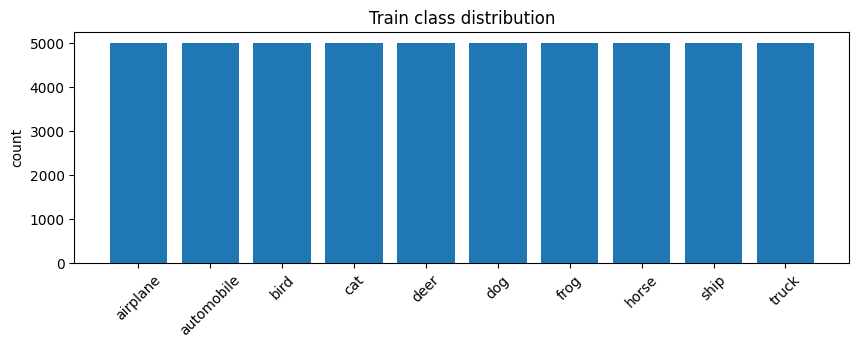

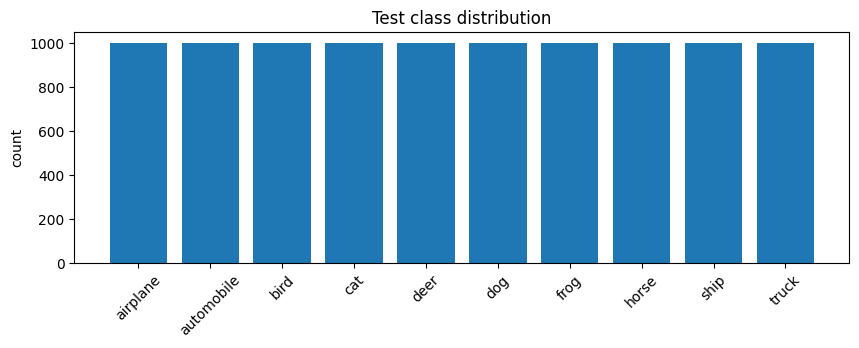

Train counts: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
Test counts : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [ ]:
train_targets = np.array(train_dataset.targets)
test_targets  = np.array(test_dataset.targets)
def plot_class_distribution(targets, title):
    counts = np.bincount(targets, minlength=num_classes)
    plt.figure(figsize=(10,3))
    plt.bar(range(num_classes), counts)
    plt.xticks(range(num_classes), class_names, rotation=45)
    plt.title(title)
    plt.ylabel("count")
    plt.show()
    return counts
train_counts = plot_class_distribution(train_targets, "Train class distribution")
test_counts  = plot_class_distribution(test_targets, "Test class distribution")
print("Train counts:", train_counts)
print("Test counts :", test_counts)

In [ ]:
def denormalize(img_tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """img_tensor: [C,H,W] in normalized space"""
    img = img_tensor.clone().cpu()
    for c in range(3):
        img[c] = img[c] * std[c] + mean[c]
    img = img.clamp(0, 1)
    return img
def show_batch(loader, class_names, n=8):
    images, labels = next(iter(loader))
    images = images[:n]
    labels = labels[:n]
    plt.figure(figsize=(16, 4))
    for i in range(n):
        img = denormalize(images[i])
        plt.subplot(1, n, i+1)
        plt.imshow(img.permute(1,2,0))
        plt.title(class_names[labels[i]])
        plt.axis("off")

    plt.show()

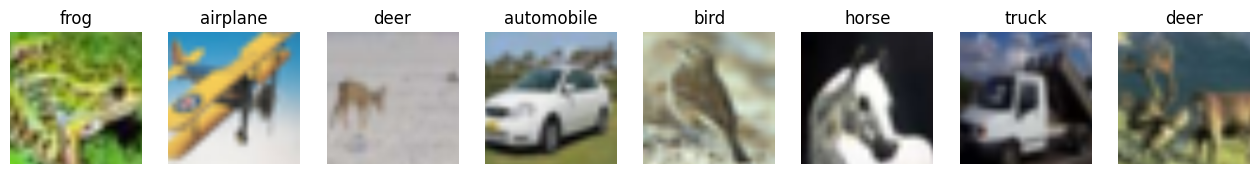

In [ ]:
show_batch(train_loader, class_names, n=8)

In [ ]:
H, W, C = 224, 224, 3
num_classes = 10

# FC: flatten -> classes
fc_params = (H*W*C) * num_classes + num_classes
print(f"[FC] params for 224x224x3 -> {num_classes}: {fc_params:,}")
# Conv 예시: 7x7 conv, in=3, out=64 (ResNet 첫 conv 비슷)
k = 7
conv_params = (k*k*C) * 64 + 64
print(f"[Conv] params for 7x7 conv (3->64): {conv_params:,}")

[FC] params for 224x224x3 -> 10: 1,505,290
[Conv] params for 7x7 conv (3->64): 9,472


In [ ]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 64.1MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
model.fc = nn.Linear(model.fc.in_features, num_classes)

FREEZE_BACKBONE_FIRST = True
if FREEZE_BACKBONE_FIRST:
    for name, param in model.named_parameters():
        if not name.startswith("fc."):
            param.requires_grad = False
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} / Total params: {total:,}")


Trainable params: 5,130 / Total params: 11,181,642


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)
print("Ready: criterion / optimizer / scheduler")

Ready: criterion / optimizer / scheduler


In [ ]:
# 배치 하나를 가져와 같은 모델에서 train/eval 출력을 비교
images, labels = next(iter(test_loader))
images = images[:4].to(device)
model.train()
with torch.no_grad():
    out_train = model(images)
model.eval()
with torch.no_grad():
    out_eval = model(images)

diff = (out_train - out_eval).abs().mean().item()
print("Mean abs diff between train-mode and eval-mode logits:", diff)

Mean abs diff between train-mode and eval-mode logits: 0.5735619068145752


#01/20  6.~

In [ ]:
from time import time

def accuracy_from_logits(logits,labels):
  preds = logits.argmax(dim = 1)
  return (preds == labels).float().mean().item()

def train_one_epoch(model,loader,optimizer,criterion):
  model.train()
  epoch_loss = 0.0
  epoch_acc = 0.0
  n_batches = 0

  t0 = time()
  for images, labels in loader:
    images = images.to(device,non_blocking = True)
    labels = labels.to(device,non_blocking = True)

    optimizer.zero_grad(set_to_none = True)
    logits = model(images)
    loss = criterion(logits, labels)

    loss.backward()
    optimizer.step()

    epoch_loss += loss.item()
    epoch_acc += accuracy_from_logits(logits, labels)
    n_batches += 1

  t1 = time()
  return epoch_loss / n_batches, epoch_acc / n_batches, (t1 - t0)

In [ ]:
@torch.no_grad()
def evaluate(model,loader,criterion):
  model.eval()
  epoch_loss = 0.0
  epoch_acc = 0.0
  n_batches = 0

  for images, labels in loader:
    images = images.to(device,non_blocking = True)
    labels = labels.to(device,non_blocking = True)

    logits = model(images)
    loss = criterion(logits, labels)

    epoch_loss += loss.item()
    epoch_acc += accuracy_from_logits(logits, labels)
    n_batches += 1

  return epoch_loss / n_batches, epoch_acc / n_batches

In [ ]:
images, labels = next(iter(test_loader))
images = images.to(device)
labels = labels.to(device)

tmp_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
tmp_model.fc = nn.Linear(tmp_model.fc.in_features, num_classes)
tmp_model = tmp_model.to(device)

In [ ]:
tmp_criterion = nn.CrossEntropyLoss()
tmp_optim = optim.SGD(tmp_model.parameters(), lr=0.05, momentum = 0.9)

tmp_model.train()
for step in range(30):
  tmp_optim.zero_grad(set_to_none = True)
  logits = tmp_model(images)
  loss = tmp_criterion(logits,labels)
  loss.backward()
  tmp_optim.step()

  acc = (logits.argmax(dim = 1) == labels).float().mean().item()
  if (step + 1) % 5 == 0:
    print(f"step {step+1:02d} | loss={loss.item():.4f} | acc={acc:.4f}")

print("Tip: acc가 0.9~1.0 근처로 올라가면 파이프라인은 대체로 정상입니다.")
print("     acc가 전혀 안 오르면: 전처리/라벨/학습률/모델 출력 차원 등을 먼저 점검하세요.")

step 05 | loss=0.2842 | acc=0.9531
step 10 | loss=0.0069 | acc=1.0000
step 15 | loss=0.0007 | acc=1.0000
step 20 | loss=0.0003 | acc=1.0000
step 25 | loss=0.0002 | acc=1.0000
step 30 | loss=0.0001 | acc=1.0000
Tip: acc가 0.9~1.0 근처로 올라가면 파이프라인은 대체로 정상입니다.
     acc가 전혀 안 오르면: 전처리/라벨/학습률/모델 출력 차원 등을 먼저 점검하세요.


In [ ]:
EPOCHS_STAGE1 = 3
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "sec": []}

for epoch in range(EPOCHS_STAGE1):
  tr_loss, tr_acc, sec = train_one_epoch(model, train_loader, optimizer, criterion)
  te_loss, te_acc = evaluate(model, test_loader, criterion)
  scheduler.step()

  history["train_loss"].append(tr_loss)
  history["train_acc"].append(tr_acc)
  history["test_loss"].append(te_loss)
  history["test_acc"].append(te_acc)
  history["sec"].append(sec)

  print(f"[Stage1][Epoch {epoch+1}/{EPOCHS_STAGE1}] "
        f"train loss: {tr_loss:.4f} | train acc: {tr_acc:.4f} | "
        f"test loss: {te_loss:.4f} | test acc: {te_acc:.4f} | "
        f"time : {sec: .1f}"
  )

[Stage1][Epoch 1/3] train loss: 0.9519 | train acc: 0.6851 | test loss: 0.7148 | test acc: 0.7586 | time :  50.3
[Stage1][Epoch 2/3] train loss: 0.7281 | train acc: 0.7482 | test loss: 0.7060 | test acc: 0.7615 | time :  50.1
[Stage1][Epoch 3/3] train loss: 0.7001 | train acc: 0.7561 | test loss: 0.6911 | test acc: 0.7607 | time :  52.3


[Stage2][Epoch 1/5] train loss=0.3248, train acc=0.8883 | test loss=0.2358, test acc=0.9208 | time=50.7s


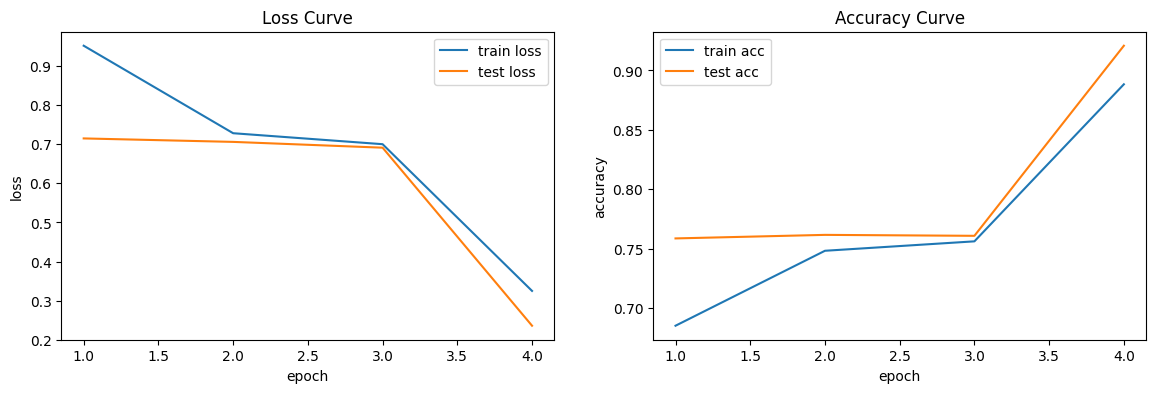

[Stage2][Epoch 2/5] train loss=0.1687, train acc=0.9408 | test loss=0.2034, test acc=0.9306 | time=51.2s


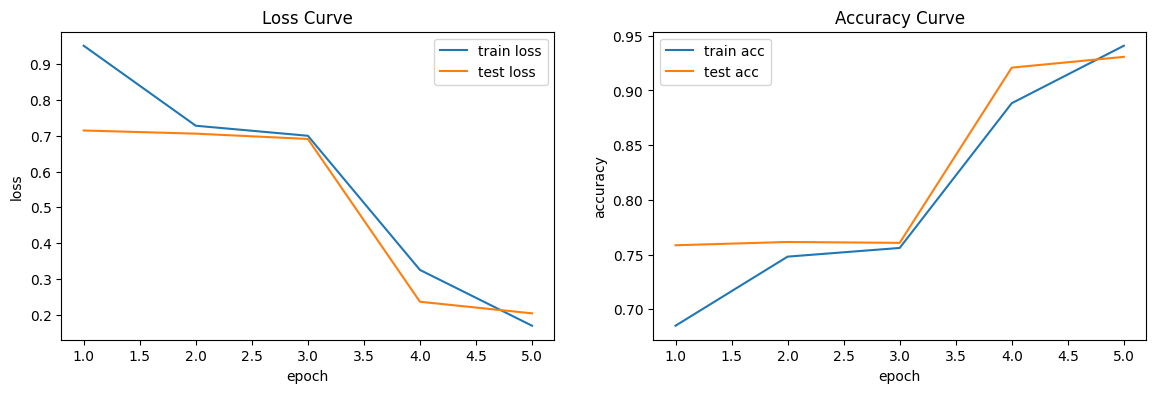

[Stage2][Epoch 3/5] train loss=0.1246, train acc=0.9556 | test loss=0.1994, test acc=0.9354 | time=49.9s


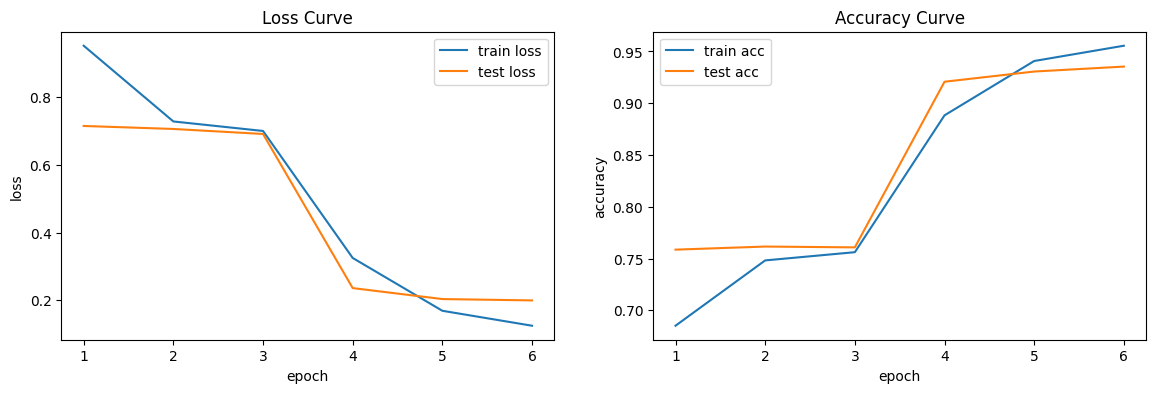

[Stage2][Epoch 4/5] train loss=0.0602, train acc=0.9807 | test loss=0.1350, test acc=0.9556 | time=51.3s


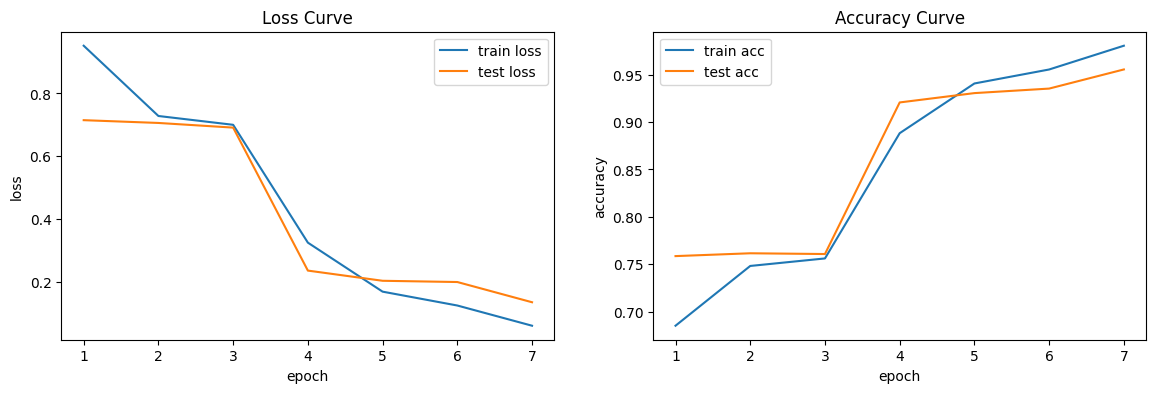

[Stage2][Epoch 5/5] train loss=0.0413, train acc=0.9870 | test loss=0.1396, test acc=0.9550 | time=49.2s


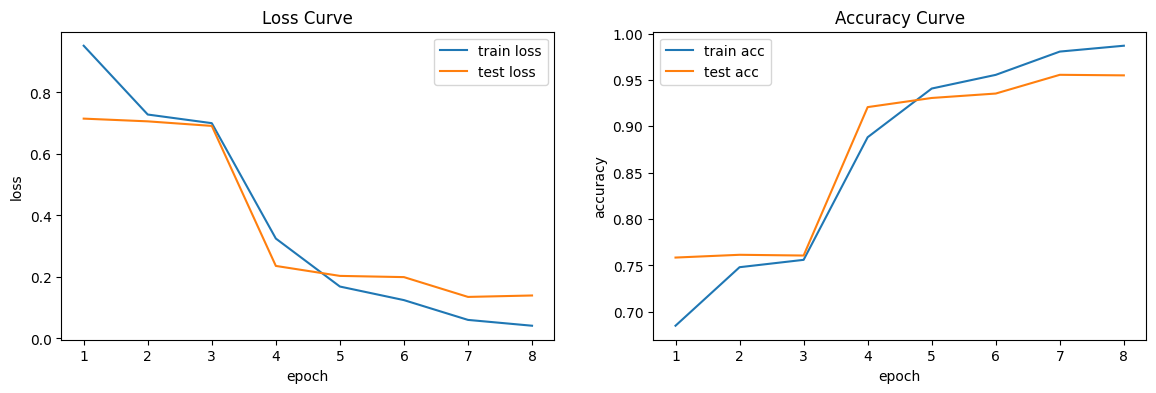

In [ ]:
for param in model.parameters():
  param.requires_grad = True

optimizer = optim.Adam(model.parameters(), lr=1e-4)
# Fixed syntax error: changed '3.' to '3,'
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)

EPOCHS_STAGE2 = 5

for epoch in range(EPOCHS_STAGE2):
  tr_loss, tr_acc, sec = train_one_epoch(model, train_loader, optimizer, criterion)
  te_loss, te_acc = evaluate(model, test_loader, criterion)
  scheduler.step()

  history["train_loss"].append(tr_loss)
  history["train_acc"].append(tr_acc)
  history["test_loss"].append(te_loss)
  history["test_acc"].append(te_acc)
  history["sec"].append(sec)

  print(f"[Stage2][Epoch {epoch+1}/{EPOCHS_STAGE2}] "
        f"train loss={tr_loss:.4f}, train acc={tr_acc:.4f} | "
        f"test loss={te_loss:.4f}, test acc={te_acc:.4f} | "
        f"time={sec:.1f}s")
  epochs = list(range(1, len(history["train_loss"]) + 1))
  plt.figure(figsize=(14,4))
  plt.subplot(1,2,1)
  plt.plot(epochs, history["train_loss"], label="train loss")
  plt.plot(epochs, history["test_loss"], label="test loss")
  plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Loss Curve")
  plt.subplot(1,2,2)
  plt.plot(epochs, history["train_acc"], label="train acc")
  plt.plot(epochs, history["test_acc"], label="test acc")
  plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("Accuracy Curve")
  plt.show()

In [ ]:
CKPT_PATH = "day1_resnet18_cifar10.pt"

torch.save({
    "model_state":model.state_dict(),
    "class_names":class_names,
    "imagenet_mean":IMAGENET_MEAN,
    "imagenet_std":IMAGENET_STD,
    "history":history,
},CKPT_PATH)

print("Saved chekpoint to:",CKPT_PATH)

Saved chekpoint to: day1_resnet18_cifar10.pt


In [ ]:
'''
ckpt = torch.load(CKPT_PATH, map_location = device)
model.load_state_dict(ckpt["model_state"])
model.to(device)
model.eval()
'''

'\nckpt = torch.load(CKPT_PATH, map_location = device)\nmodel.load_state_dict(ckpt["model_state"])\nmodel.to(device)\nmodel.eval()\n'

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
@torch.no_grad()
def get_predictions(model, loader):
  model.eval()
  all_preds = []
  all_labels = []
  all_probs = []

  softmax = nn.Softmax(dim=1)

  for images, labels in loader:
    images = images.to(device,non_blocking = True)
    logits = model(images)
    probs = softmax(logits).cpu().numpy()
    preds = logits.argmax(dim=1).cpu().numpy()

    all_probs.append(probs)
    all_preds.append(preds)
    all_labels.append(labels.numpy())

  all_probs = np.concatenate(all_probs, axis = 0)
  all_preds = np.concatenate(all_preds, axis = 0)
  all_labels = np.concatenate(all_labels, axis = 0)

  return all_preds, all_labels, all_probs

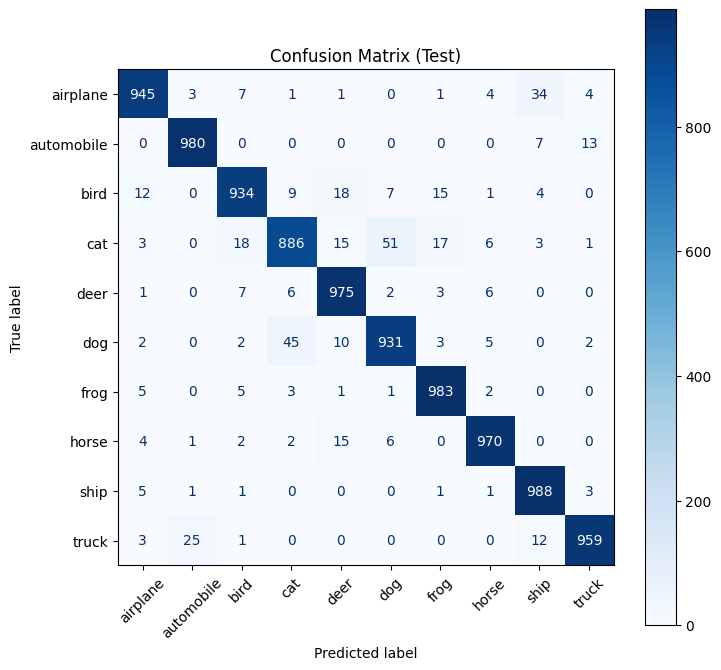

In [ ]:
preds, labels, probs = get_predictions(model, test_loader)
# Fixed typo: np.arrange -> np.arange
cm = confusion_matrix(labels, preds, labels=np.arange(num_classes))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8,8))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Test)")
plt.show()

In [ ]:
mis_idx = np.where(preds != labels)[0]
# Fixed SyntaxError: replaced dot with comma
print("Misclassified:", len(mis_idx), " / ", len(labels))

def show_misclassified(test_dataset, mis_idx, probs, preds, labels, class_names, n=12):
  n = min(n, len(mis_idx))
  chosen = np.random.choice(mis_idx, size = n, replace = False)
  plt.figure(figsize=(18, 8))
  for i, idx in enumerate(chosen):
    img, true_label = test_dataset[idx]
    pred_label = preds[idx]
    pred_prob = probs[idx, pred_label]
    img_vis = denormalize(img).permute(1,2,0).numpy()
    plt.subplot(3, 4, i+1)
    plt.imshow(img_vis)
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]} ({pred_prob:.2f})")
  plt.tight_layout()
  plt.show()

Misclassified: 449  /  10000


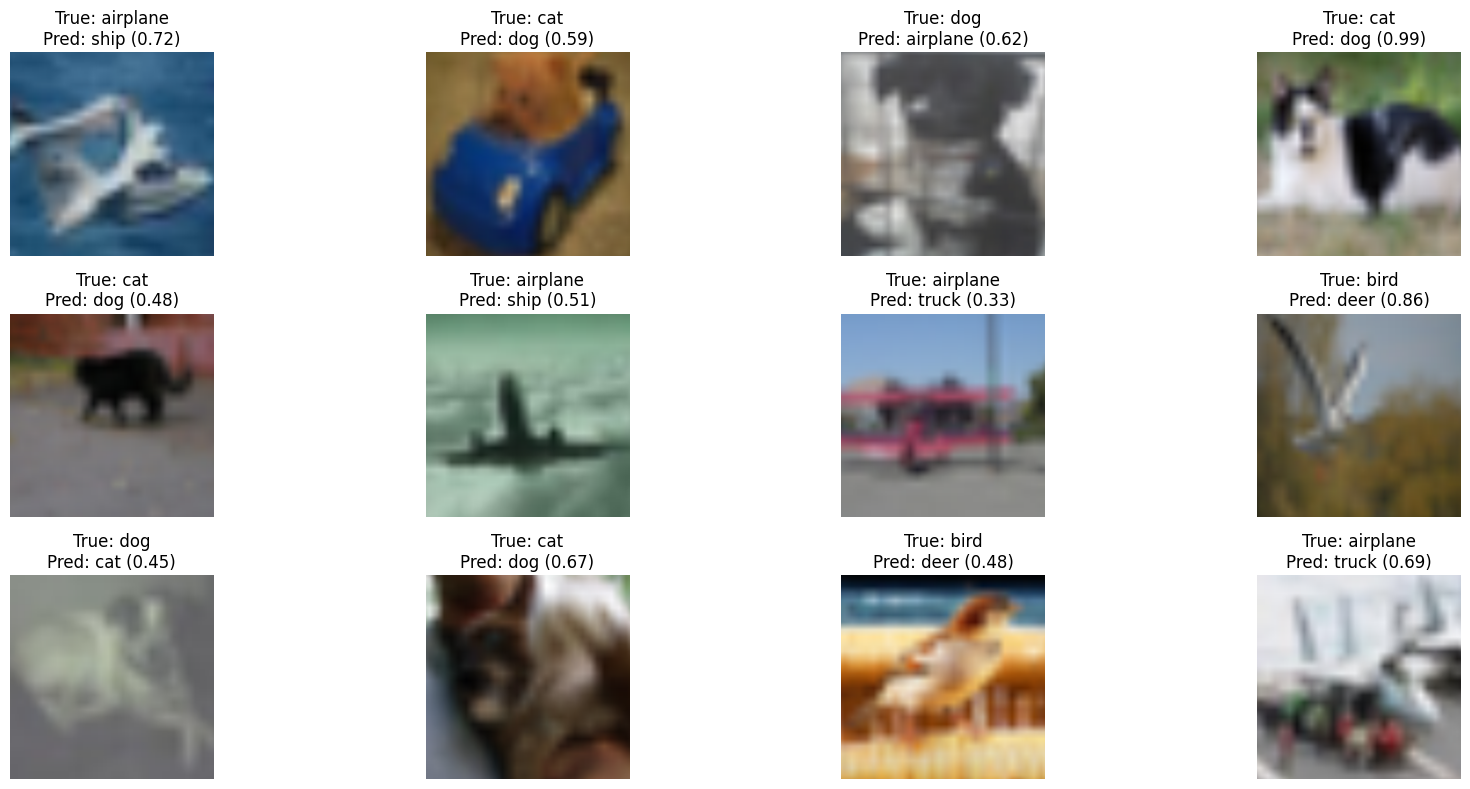

In [ ]:
show_misclassified(test_dataset, mis_idx, probs, preds, labels, class_names, n=12)

In [ ]:
from collections import OrderedDict

In [ ]:
# Redefining the class to fix the AttributeError (save_activation -> _make_hook)
class ActivationRecorder:
  def __init__(self, model, layer_names):
    self.model = model
    self.layer_names = set(layer_names)
    self.activations = OrderedDict()
    self.hooks = []

    for name, module in model.named_modules():
      if name in self.layer_names:
        # Fixed: used self._make_hook instead of self.save_activation
        self.hooks.append(module.register_forward_hook(self._make_hook(name)))

  def _make_hook(self, name):
    def hook(module, inp, out):
      self.activations[name] = out.detach()
    return hook

  def clear(self):
       self.activations = OrderedDict()

  def remove(self):
      for h in self.hooks:
        h.remove()

In [ ]:
layer_names = [
    "conv1",
    "layer1.0.conv1",
    "layer2.0.conv1",
    "layer3.0.conv1",
    "layer4.1.conv2"
    ]

In [ ]:
rec = ActivationRecorder(model, layer_names)
print("Recorder ready for:", layer_names)

Recorder ready for: ['conv1', 'layer1.0.conv1', 'layer2.0.conv1', 'layer3.0.conv1', 'layer4.1.conv2']


In [ ]:
model.eval()

idx = 0
img, y = test_dataset[idx]
x = img.unsqueeze(0).to(device)

rec.clear()
with torch.no_grad():
  logits = model(x)


pred = logits.argmax(dim=1).item()
print("True:",class_names[y],"| Pred::",class_names[pred])

for k, v in rec.activations.items():
  print(k, tuple(v.shape))

True: cat | Pred:: cat
conv1 (1, 64, 112, 112)
layer1.0.conv1 (1, 64, 56, 56)
layer2.0.conv1 (1, 128, 28, 28)
layer3.0.conv1 (1, 256, 14, 14)
layer4.1.conv2 (1, 512, 7, 7)


##Feature Map 보는 법
- 어떤 채널이 강하게 활성화?
- 객체 중심? 배경 중심?
- 깊이에 따른 pattern 변화

In [ ]:
def show_feature_maps(act_tensor, max_channels = 12, title=""):
  """act_tensor: [1, C, H, W]"""
  act = act_tensor[0].cpu()
  C = act.shape[0]
  n = min(max_channels, C)

  cols = 6
  rows = int(np.ceil(n / cols))

  plt.figure(figsize=(16,3*rows))
  for i in range(n):
    plt.subplot(rows, cols, i+1)
    plt.imshow(act[i], cmap="viridis")
    plt.axis("off")
    plt.title(f"ch {i}")
  plt.suptitle(title, y=1.02, fontsize=14)
  plt.tight_layout()
  plt.show()

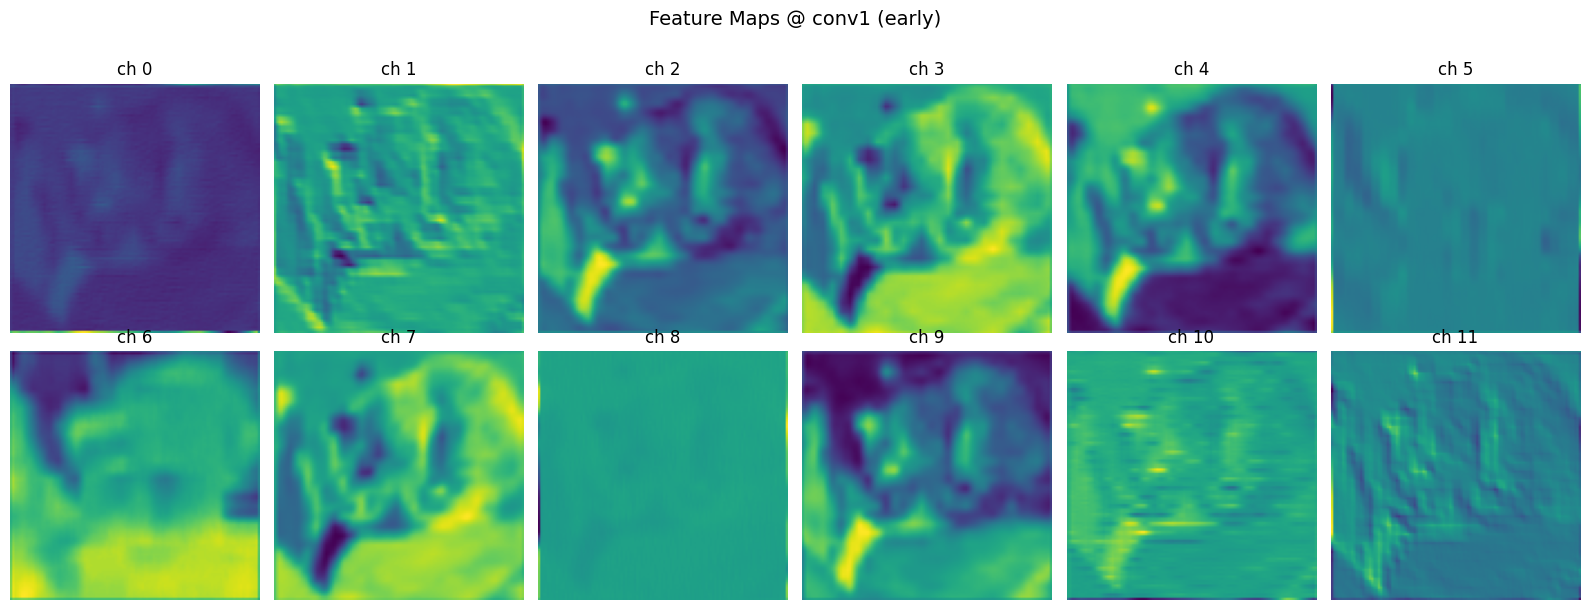

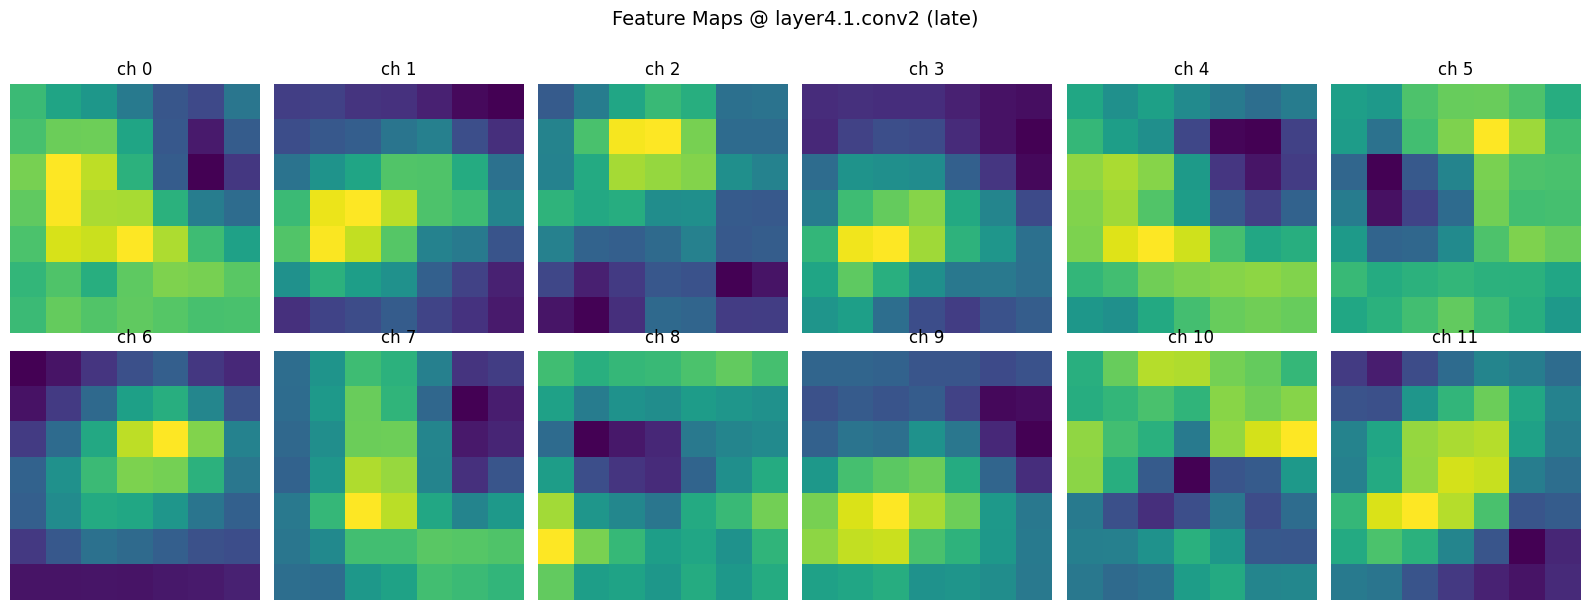

In [ ]:
show_feature_maps(rec.activations["conv1"], max_channels=12, title="Feature Maps @ conv1 (early)")
show_feature_maps(rec.activations["layer4.1.conv2"], max_channels=12, title="Feature Maps @ layer4.1.conv2 (late)")

In [ ]:
import torch.nn.functional as F

class GradCAM:
  def __init__(self, model, target_layer_name):
    self.model = model
    self.target_layer_name = target_layer_name
    self.activation = None
    self.gradient = None
    self.hook = None

    self.target_layer = None
    # Fixed: self.model.named_modules() instead of self.named_modules()
    for name, module in self.model.named_modules():
      if name == target_layer_name:
        self.target_layer = module
        break
    if self.target_layer is None:
      raise ValueError(f"Target layer '{target_layer_name}' not found.")

    # Defined hook inside init with correct indentation
    def forward_hook(module, inp, out):
      self.activation = out
      out.register_hook(self._save_gradient)

    self.hook = self.target_layer.register_forward_hook(forward_hook)

  def _save_gradient(self, grad):
    self.gradient = grad

  def remove(self):
    if self.hook is not None:
      self.hook.remove()

  def __call__(self, x, class_idx=None):
    self.model.eval()
    self.model.zero_grad(set_to_none=True)

    logits = self.model(x)

    if class_idx is None:
      class_idx = logits.argmax(dim=1).item()

    score = logits[0, class_idx]
    # Fixed: removed double parentheses
    score.backward(retain_graph=True)

    act = self.activation.detach()
    grad = self.gradient.detach()

    weights = grad.mean(dim=(2,3), keepdim=True)
    cam = (weights * act).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    return cam, class_idx, logits.detach()

In [ ]:
import cv2
def overlay_cam_on_image(img_tensor_norm, cam_1x1hw, alpha=0.4):
    img = denormalize(img_tensor_norm).permute(1,2,0).numpy()  # 0~1
    img_u8 = np.uint8(img * 255)
    cam = cam_1x1hw[0,0].cpu().numpy()
    cam = cv2.resize(cam, (img_u8.shape[1], img_u8.shape[0]))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = np.clip((1 - alpha) * img_u8 + alpha * heatmap, 0, 255).astype(np.uint8)
    return overlay

target_layer_name = "layer4.1.conv2"
gradcam = GradCAM(model, target_layer_name)
print("Target layer for Grad-CAM:", target_layer_name)

Target layer for Grad-CAM: layer4.1.conv2


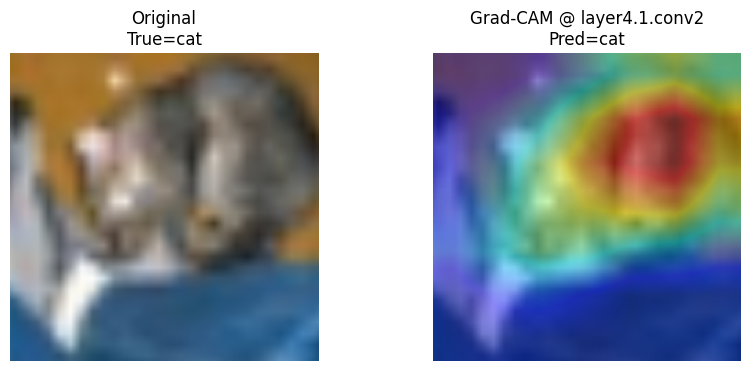

In [ ]:
idx = 0
img, y = test_dataset[idx]
x = img.unsqueeze(0).to(device)
cam, class_idx, logits = gradcam(x, class_idx=None)
pred = class_idx
overlay = overlay_cam_on_image(img, cam, alpha=0.45)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(denormalize(img).permute(1,2,0))
plt.axis("off")
plt.title(f"Original\nTrue={class_names[y]}")
plt.subplot(1,2,2)
plt.imshow(overlay)
plt.axis("off")
plt.title(f"Grad-CAM @ {target_layer_name}\nPred={class_names[pred]}")
plt.show()

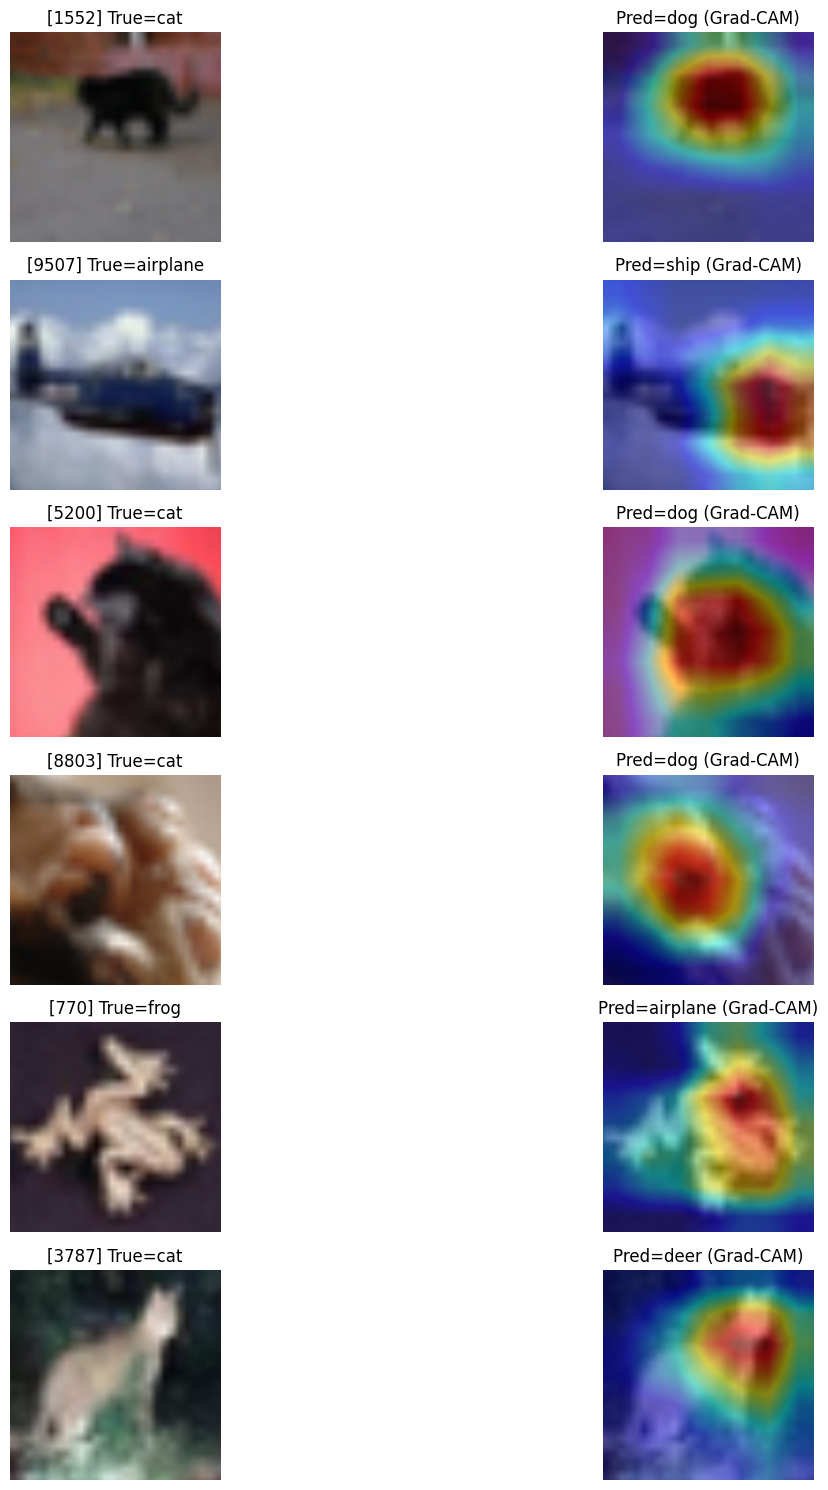

In [ ]:
def show_gradcam_on_misclassified(test_dataset, mis_idx, n=8):
    chosen = np.random.choice(mis_idx, size=min(n, len(mis_idx)), replace=False)
    plt.figure(figsize=(16, 2.5*len(chosen)))
    for i, idx in enumerate(chosen):
        img, y = test_dataset[idx]
        x = img.unsqueeze(0).to(device)
        cam, pred, logits = gradcam(x, class_idx=None)
        overlay = overlay_cam_on_image(img, cam, alpha=0.45)
        plt.subplot(len(chosen), 2, 2*i + 1)
        plt.imshow(denormalize(img).permute(1,2,0))
        plt.axis("off")
        plt.title(f"[{idx}] True={class_names[y]}")
        plt.subplot(len(chosen), 2, 2*i + 2)
        plt.imshow(overlay)
        plt.axis("off")
        plt.title(f"Pred={class_names[pred]} (Grad-CAM)")
    plt.tight_layout()
    plt.show()
show_gradcam_on_misclassified(test_dataset, mis_idx, n=6)

 과제 A(필수)
1. confustion matrix를 보고 가장 헷갈리는 클래스 쌍 1개를 선택 (필수)
2. 그 쌍의 오분류 샘플 20장을 모아 "왜 헷갈리는지"를 서술 (필수)
3. Grad-CAM을 최소 10장에 적용해, 모델이 보는 근거를 설명 (필수)
4. 개선 아이디어 2개를 제안(데이터/증강/학습 설정 중심) (선택)

 과제 B(선택)
1. augmentation을 하나 추가/변경하고, 혼동되는 클래스가 개선되는지 확인
2. backbone freeze vs unfreeze 비교 (학습 곡선과 misclassification 비교)


In [ ]:
confused_pairs = []
for i in range(num_classes):
    for j in range(num_classes):
        if i != j and cm[i, j] > 0:
            confused_pairs.append((cm[i, j], class_names[i], class_names[j]))

# Sort by count (descending)
confused_pairs.sort(key=lambda x: x[0], reverse=True)

print("=== Top Confused Pairs (True -> Pred) ===")
for count, true_cls, pred_cls in confused_pairs[:15]:
    print(f"{true_cls:10s} -> {pred_cls:10s} : {count} times")

=== Top Confused Pairs (True -> Pred) ===
cat        -> dog        : 51 times
dog        -> cat        : 45 times
airplane   -> ship       : 34 times
truck      -> automobile : 25 times
bird       -> deer       : 18 times
cat        -> bird       : 18 times
cat        -> frog       : 17 times
bird       -> frog       : 15 times
cat        -> deer       : 15 times
horse      -> deer       : 15 times
automobile -> truck      : 13 times
bird       -> airplane   : 12 times
truck      -> ship       : 12 times
dog        -> deer       : 10 times
bird       -> cat        : 9 times


In [ ]:
# 1. Verify Dataset Balance
print(f"Train counts per class: {train_counts}")
print(f"Test counts per class : {test_counts}")
print("Dataset is perfectly balanced.\n")

# 2. Check Symmetry of Confusion
print("=== Confusion Symmetry Check (A->B vs B->A) ===")
checked_pairs = set()

for count, true_cls, pred_cls in confused_pairs[:10]:
    pair_key = tuple(sorted((true_cls, pred_cls)))
    if pair_key in checked_pairs:
        continue
    checked_pairs.add(pair_key)

    # Get indices
    i = class_names.index(true_cls)
    j = class_names.index(pred_cls)

    # Count A->B and B->A
    count_a_b = cm[i, j]
    count_b_a = cm[j, i]

    print(f"{true_cls:10s} <-> {pred_cls:10s} | {true_cls}->{pred_cls}: {count_a_b:<3} vs {pred_cls}->{true_cls}: {count_b_a:<3}")

Train counts per class: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
Test counts per class : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
Dataset is perfectly balanced.

=== Confusion Symmetry Check (A->B vs B->A) ===
cat        <-> dog        | cat->dog: 51  vs dog->cat: 45 
airplane   <-> ship       | airplane->ship: 34  vs ship->airplane: 5  
truck      <-> automobile | truck->automobile: 25  vs automobile->truck: 13 
bird       <-> deer       | bird->deer: 18  vs deer->bird: 7  
cat        <-> bird       | cat->bird: 18  vs bird->cat: 9  
cat        <-> frog       | cat->frog: 17  vs frog->cat: 3  
bird       <-> frog       | bird->frog: 15  vs frog->bird: 5  
cat        <-> deer       | cat->deer: 15  vs deer->cat: 6  
horse      <-> deer       | horse->deer: 15  vs deer->horse: 6  


##고양이의 필터가 강한가? VS 나머지 필터가 약한가?


=== Prediction Bias Check ===
Class      | True   | Pred   | Bias (Pred - True)
---------------------------------------------
airplane   | 1000   | 980    | -20
automobile | 1000   | 1010   | +10
bird       | 1000   | 977    | -23
cat        | 1000   | 952    | -48
deer       | 1000   | 1035   | +35
dog        | 1000   | 998    | -2
frog       | 1000   | 1023   | +23
horse      | 1000   | 995    | -5
ship       | 1000   | 1048   | +48
truck      | 1000   | 982    | -18


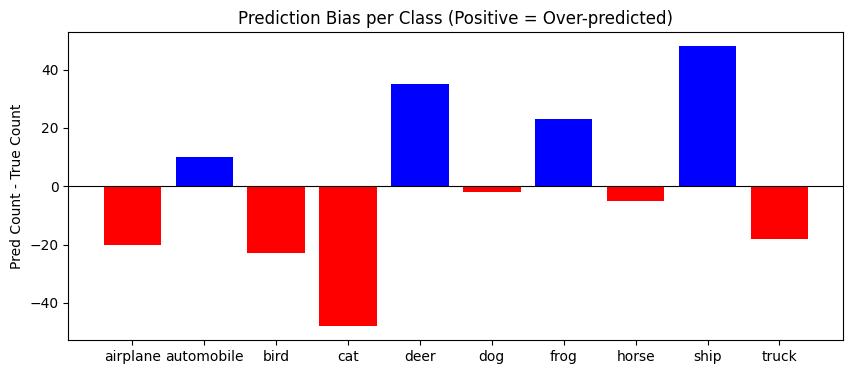

In [ ]:
# 1. Check Prediction Bias (Total Predicted Counts vs True Counts)
pred_counts = np.bincount(preds, minlength=num_classes)
true_counts = np.bincount(labels, minlength=num_classes)

print("=== Prediction Bias Check ===")
print(f"{'Class':<10} | {'True':<6} | {'Pred':<6} | {'Bias (Pred - True)'}")
print("-"*45)
for i, name in enumerate(class_names):
    bias = pred_counts[i] - true_counts[i]
    print(f"{name:<10} | {true_counts[i]:<6} | {pred_counts[i]:<6} | {bias:+d}")

# Visualize Bias
plt.figure(figsize=(10, 4))
plt.bar(class_names, pred_counts - true_counts, color=['red' if x < 0 else 'blue' for x in (pred_counts - true_counts)])
plt.axhline(0, color='black', linewidth=0.8)
plt.title("Prediction Bias per Class (Positive = Over-predicted)")
plt.ylabel("Pred Count - True Count")
plt.show()

## 오히려 고양이는 필터가 약하다!
1. "고양이 필터가 강하다"는 가설은 기각 (Bias: -48)
데이터 해석: 실제 고양이는 1,000마리인데, 모델이 고양이라고 예측한 건 952번뿐입니다. (-48 부족)
의미: 모델은 애매하면 고양이라고 우기는 게 아니라, 오히려 진짜 고양이조차 다른 것(주로 개)으로 잘못 판단하고 있습니다.
반대로 강한 필터: ship(+48)이나 deer(+35)입니다. 이들은 애매한 것들을 자기네 클래스로 끌어당기는 '공격적인' 성향을 보입니다.
2. 왜 헷갈리는가? (Cat <-> Dog)
대칭적인 혼동: 고양이가 개로(51회), 개가 고양이로(45회) 가는 비율이 비슷합니다. 이는 한쪽이 압도하는 관계가 아니라, 두 클래스의 경계선이 모호함을 의미합니다.
높은 확신(0.99): 틀린 샘플들 중 확률이 **99%**에 달하는 경우가 있다는 것은, 모델이 "이건 확실히 개다!"라고 생각했는데 실제로는 고양이였다는 뜻입니다.
이유: 모델이 '귀 모양'이나 '주둥이' 같은 결정적 특징(Discriminative Feature)을 못 보고, **"털이 있고 다리가 4개면 개"**라는 식의 **공통된 특징(Shared Feature)**에 과도하게 의존했을 가능성이 큽니다.

Target Layer: layer4.1.conv2


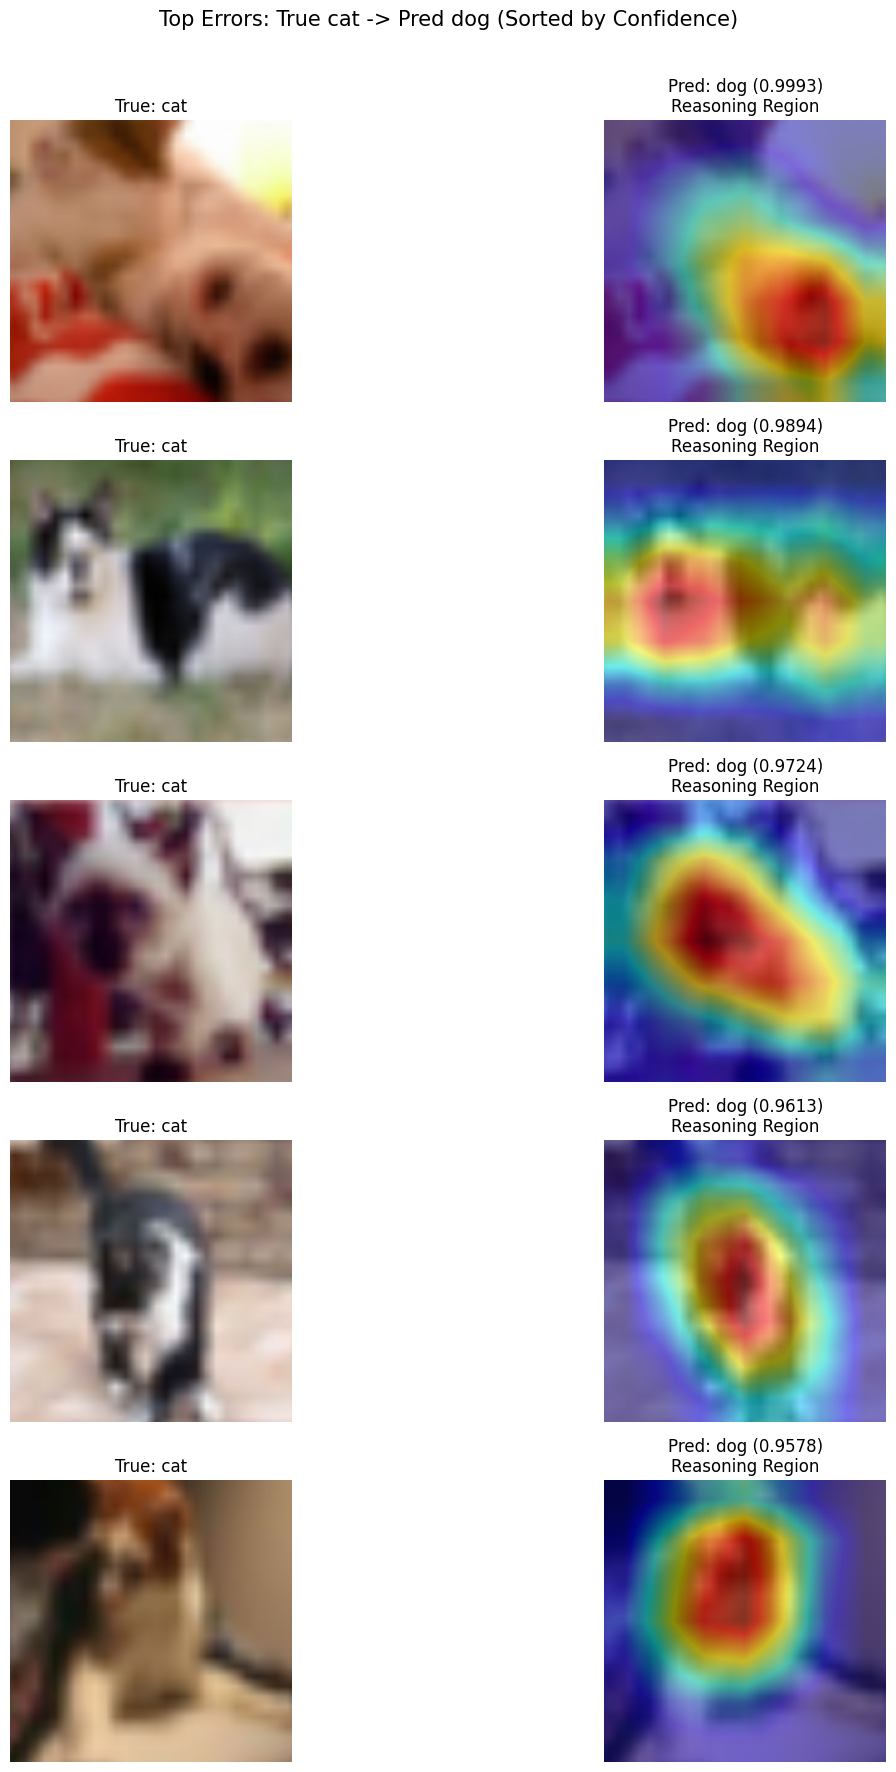

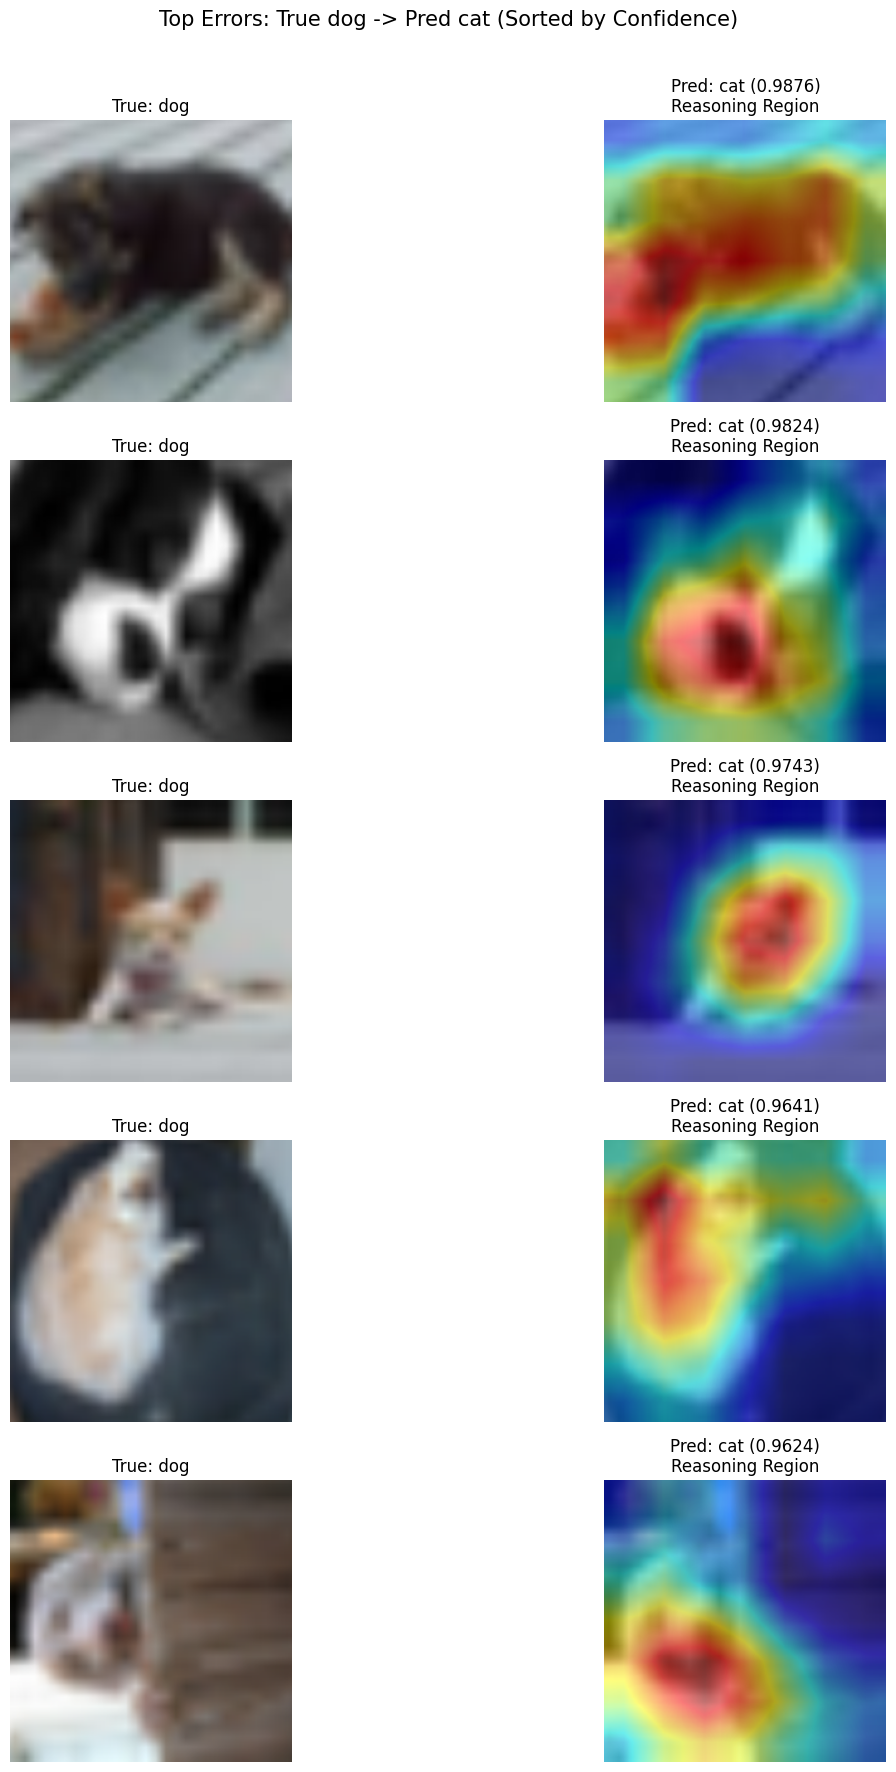

In [ ]:
# 1. Get Top Confusion Pair
top_true_name = confused_pairs[0][1]  # 'cat'
top_pred_name = confused_pairs[0][2]  # 'dog'

top_true_idx = class_names.index(top_true_name)
top_pred_idx = class_names.index(top_pred_name)

# 2. Find indices and sort by confidence
def get_sorted_errors(true_idx, pred_idx):
    # Find all indices where True=true_idx AND Pred=pred_idx
    mistakes = np.where((labels == true_idx) & (preds == pred_idx))[0]
    # Get confidence for each mistake
    confidences = probs[mistakes, pred_idx]
    # Sort by confidence descending
    sorted_indices = mistakes[np.argsort(confidences)[::-1]]
    return sorted_indices

cat_to_dog_indices = get_sorted_errors(top_true_idx, top_pred_idx)
dog_to_cat_indices = get_sorted_errors(top_pred_idx, top_true_idx)

# 3. Visualization Function
def show_gradcam_on_errors(indices, title_prefix, n=5):
    if len(indices) == 0: return

    # Pick top n confident errors
    chosen = indices[:n]

    plt.figure(figsize=(15, 3.5 * len(chosen)))

    for i, idx in enumerate(chosen):
        # Load data
        img, y = test_dataset[idx]
        x = img.unsqueeze(0).to(device)

        # Run Grad-CAM
        # We want to see why it predicted the WRONG class, so target class_idx = pred_label
        pred_label = preds[idx]
        confidence = probs[idx, pred_label]

        cam, _, _ = gradcam(x, class_idx=pred_label)
        overlay = overlay_cam_on_image(img, cam, alpha=0.5)

        # Plot Original
        plt.subplot(len(chosen), 2, 2*i + 1)
        plt.imshow(denormalize(img).permute(1,2,0))
        plt.axis("off")
        plt.title(f"True: {class_names[y]}")

        # Plot Grad-CAM
        plt.subplot(len(chosen), 2, 2*i + 2)
        plt.imshow(overlay)
        plt.axis("off")
        plt.title(f"Pred: {class_names[pred_label]} ({confidence:.4f})\nReasoning Region")

    plt.suptitle(f"{title_prefix} (Sorted by Confidence)", y=1.01, fontsize=15)
    plt.tight_layout()
    plt.show()

# 4. Execute
print(f"Target Layer: {gradcam.target_layer_name}")
show_gradcam_on_errors(cat_to_dog_indices, title_prefix=f"Top Errors: True {top_true_name} -> Pred {top_pred_name}", n=5)
show_gradcam_on_errors(dog_to_cat_indices, title_prefix=f"Top Errors: True {top_pred_name} -> Pred {top_true_name}", n=5)

## Reasoning Region을 보면 웅크리고 있는게 많아보인다.


=== Visualizing Confusion: cat vs dog ===


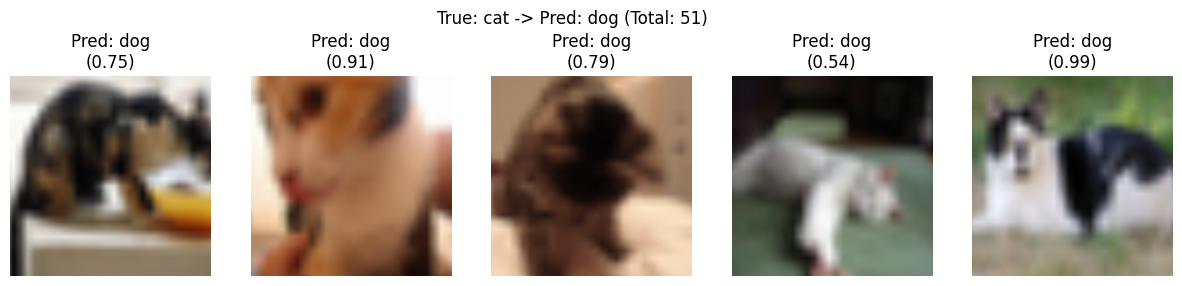

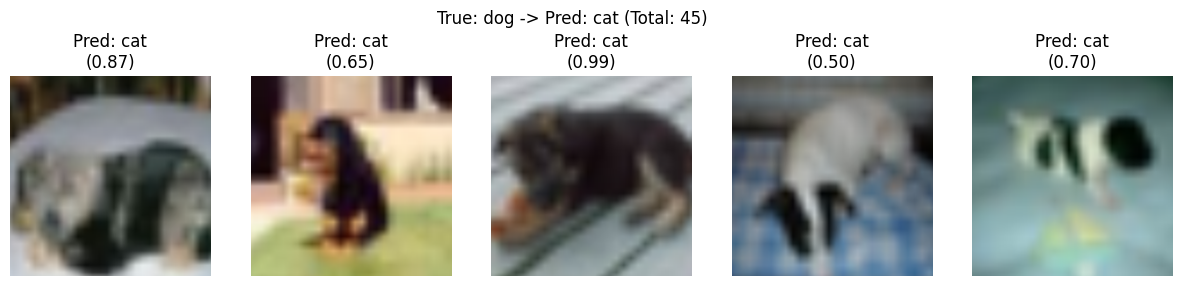

In [ ]:
# 2. Visualize the specific confusion of the Top-1 Pair
top_true, top_pred = confused_pairs[0][1], confused_pairs[0][2]
top_true_idx = class_names.index(top_true)
top_pred_idx = class_names.index(top_pred)

print(f"\n=== Visualizing Confusion: {top_true} vs {top_pred} ===")

# Case A: True=A, Pred=B
idx_A_to_B = np.where((labels == top_true_idx) & (preds == top_pred_idx))[0]
# Case B: True=B, Pred=A
idx_B_to_A = np.where((labels == top_pred_idx) & (preds == top_true_idx))[0]

def show_confusion_samples(indices, title, n=5):
    if len(indices) == 0: return
    plt.figure(figsize=(15, 3))
    chosen = np.random.choice(indices, size=min(n, len(indices)), replace=False)
    for i, idx in enumerate(chosen):
        img = test_dataset[idx][0]
        prob = probs[idx, preds[idx]]
        plt.subplot(1, n, i+1)
        plt.imshow(denormalize(img).permute(1,2,0))
        plt.axis('off')
        plt.title(f"Pred: {class_names[preds[idx]]}\n({prob:.2f})")
    plt.suptitle(title + f" (Total: {len(indices)})", y=1.05)
    plt.show()

show_confusion_samples(idx_A_to_B, f"True: {top_true} -> Pred: {top_pred}")
show_confusion_samples(idx_B_to_A, f"True: {top_pred} -> Pred: {top_true}")

In [ ]:
train_transform_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=train_transform_aug
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)

print("Data loaders updated with RandomResizedCrop augmentation.")

Data loaders updated with RandomResizedCrop augmentation.


=== Stage 1: Frozen Backbone Training ===
Epoch 1/3 | Train Loss: 0.8941 Acc: 0.7078 | Test Loss: 0.7504 Acc: 0.7451 | Time: 76.7s
Epoch 2/3 | Train Loss: 0.6811 Acc: 0.7652 | Test Loss: 0.7209 Acc: 0.7541 | Time: 76.1s
Epoch 3/3 | Train Loss: 0.6526 Acc: 0.7726 | Test Loss: 0.7497 Acc: 0.7462 | Time: 77.0s

=== Stage 2: Fine-tuning (All Layers) ===
Epoch 1/5 | Train Loss: 0.3004 Acc: 0.8967 | Test Loss: 0.2301 Acc: 0.9227 | Time: 77.1s
Epoch 2/5 | Train Loss: 0.1561 Acc: 0.9466 | Test Loss: 0.2034 Acc: 0.9299 | Time: 76.6s
Epoch 3/5 | Train Loss: 0.1132 Acc: 0.9605 | Test Loss: 0.2106 Acc: 0.9298 | Time: 76.1s
Epoch 4/5 | Train Loss: 0.0539 Acc: 0.9822 | Test Loss: 0.1487 Acc: 0.9506 | Time: 77.8s
Epoch 5/5 | Train Loss: 0.0328 Acc: 0.9900 | Test Loss: 0.1477 Acc: 0.9505 | Time: 76.5s


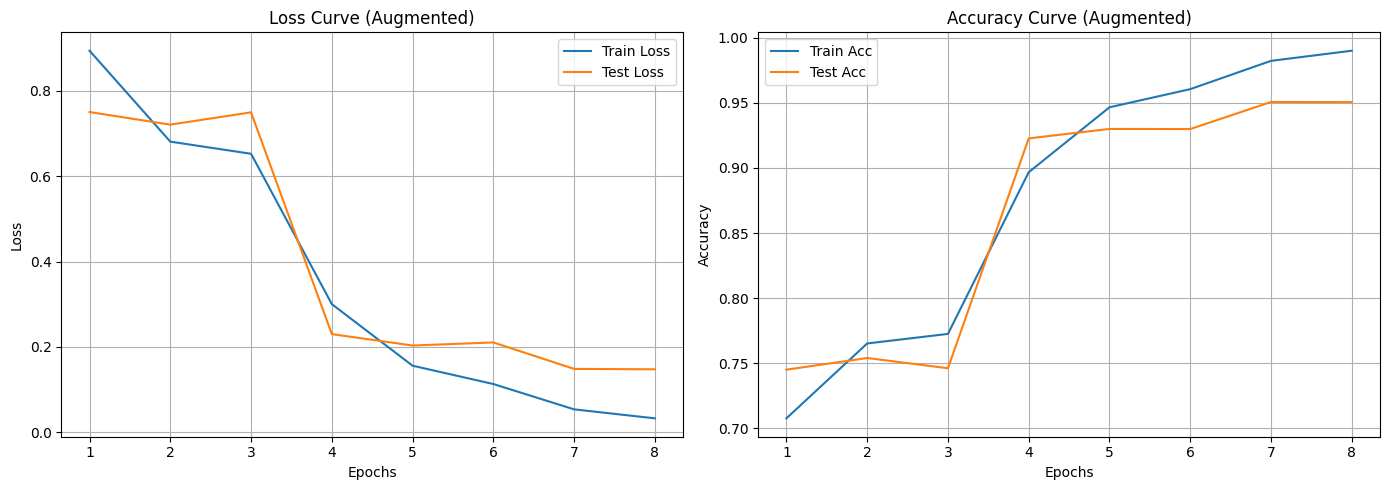

In [ ]:
# 1. Initialize ResNet18 with ImageNet weights
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# 2. Stage 1: Frozen Backbone
print("=== Stage 1: Frozen Backbone Training ===")
# Freeze all except fc
for name, param in model.named_parameters():
    if not name.startswith("fc."):
        param.requires_grad = False

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "sec": []}
EPOCHS_STAGE1 = 3

for epoch in range(EPOCHS_STAGE1):
    tr_loss, tr_acc, sec = train_one_epoch(model, train_loader, optimizer, criterion)
    te_loss, te_acc = evaluate(model, test_loader, criterion)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["test_loss"].append(te_loss)
    history["test_acc"].append(te_acc)
    history["sec"].append(sec)

    print(f"Epoch {epoch+1}/{EPOCHS_STAGE1} | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
          f"Test Loss: {te_loss:.4f} Acc: {te_acc:.4f} | Time: {sec:.1f}s")

# 4. Stage 2: Fine-tuning
print("\n=== Stage 2: Fine-tuning (All Layers) ===")
# Unfreeze all parameters
for param in model.parameters():
    param.requires_grad = True

# Re-initialize optimizer for all parameters with lower learning rate
optimizer = optim.Adam(model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)

EPOCHS_STAGE2 = 5
for epoch in range(EPOCHS_STAGE2):
    tr_loss, tr_acc, sec = train_one_epoch(model, train_loader, optimizer, criterion)
    te_loss, te_acc = evaluate(model, test_loader, criterion)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["test_loss"].append(te_loss)
    history["test_acc"].append(te_acc)
    history["sec"].append(sec)

    print(f"Epoch {epoch+1}/{EPOCHS_STAGE2} | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
          f"Test Loss: {te_loss:.4f} Acc: {te_acc:.4f} | Time: {sec:.1f}s")

# 6. Plot Results
epochs_range = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label='Train Loss')
plt.plot(epochs_range, history["test_loss"], label='Test Loss')
plt.title('Loss Curve (Augmented)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], label='Train Acc')
plt.plot(epochs_range, history["test_acc"], label='Test Acc')
plt.title('Accuracy Curve (Augmented)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Evaluate & Grad-CAM Analysis

### Subtask:
Evaluate the retrained model using the confusion matrix and analyze misclassifications using Grad-CAM.


**Reasoning**:
Generate predictions for the retrained model using the test set and visualize the confusion matrix to evaluate performance improvements.



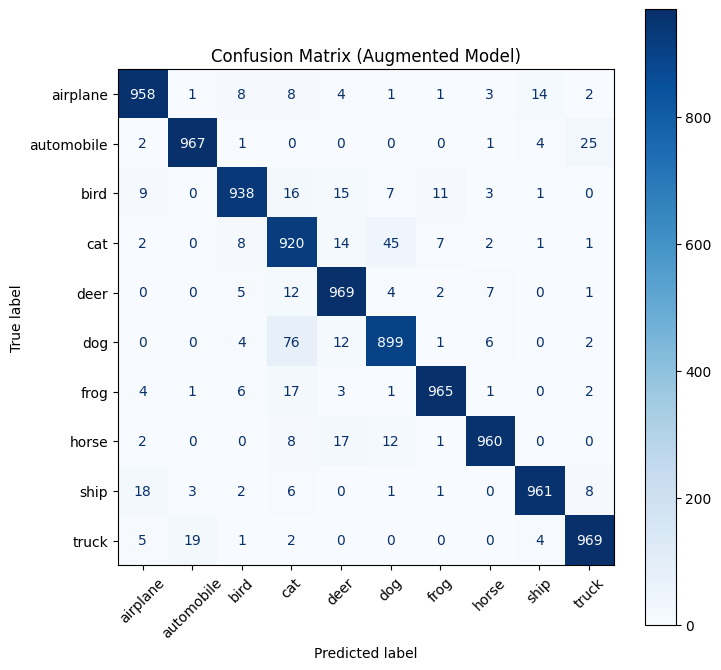

In [ ]:
# 1. Get predictions for the augmented model
preds, labels, probs = get_predictions(model, test_loader)

# 2. Compute and Plot Confusion Matrix
cm = confusion_matrix(labels, preds, labels=np.arange(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(8,8))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Augmented Model)")
plt.show()

##모든 클래스에 대해서 공정하게 Augmentation을 진행했는데 왜 Dog와 Cat 사이를 비교하는 퍼포먼스가 떨어졌을까?
-> RandomResizedCrop으로 인해 고양이나 개의 고유한 판별능력은 오히려 떨어질 수도 있다.

Top Confused Pair (Augmented): True dog -> Pred cat (76 errors)
Visualizing top 5 misclassified examples for dog -> cat...


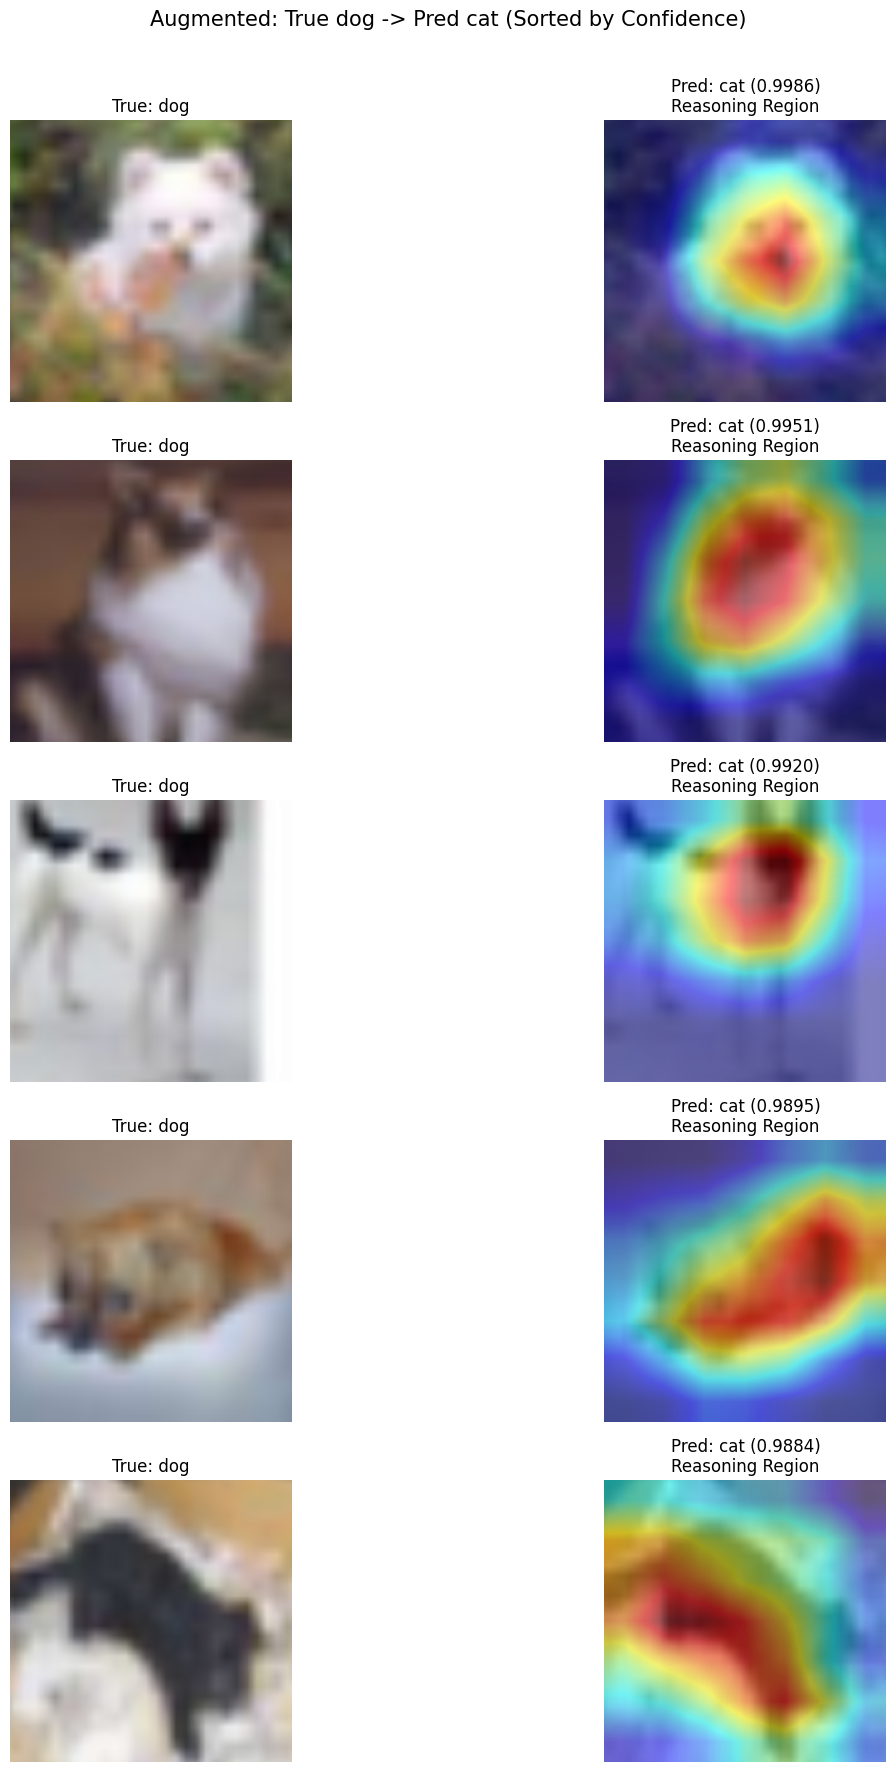

In [ ]:
# 1. Identify Top Confused Pair from the new Confusion Matrix
confused_pairs = []
for i in range(num_classes):
    for j in range(num_classes):
        if i != j and cm[i, j] > 0:
            confused_pairs.append((cm[i, j], class_names[i], class_names[j]))

confused_pairs.sort(key=lambda x: x[0], reverse=True)
top_count, top_true, top_pred = confused_pairs[0]
print(f"Top Confused Pair (Augmented): True {top_true} -> Pred {top_pred} ({top_count} errors)")

# 2. Re-initialize GradCAM for the current (augmented) model
# This updates the global 'gradcam' object used by 'show_gradcam_on_errors'
target_layer_name = "layer4.1.conv2"
gradcam = GradCAM(model, target_layer_name)

# 3. Retrieve indices for the top confused pair
top_true_idx = class_names.index(top_true)
top_pred_idx = class_names.index(top_pred)

mistakes = np.where((labels == top_true_idx) & (preds == top_pred_idx))[0]

# Sort by confidence of the wrong prediction to see the "strongest" errors
mistake_probs = probs[mistakes, top_pred_idx]
sorted_indices = mistakes[np.argsort(mistake_probs)[::-1]]

# 4. Visualize Grad-CAM for the top 5 errors
print(f"Visualizing top 5 misclassified examples for {top_true} -> {top_pred}...")
show_gradcam_on_errors(sorted_indices, title_prefix=f"Augmented: True {top_true} -> Pred {top_pred}", n=5)

###

## Train Deeper Model (ResNet34)


=== Initializing ResNet34 ===
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:02<00:00, 36.0MB/s]



=== Stage 1: Frozen Backbone (ResNet34) ===
Epoch 1/3 | Train Loss: 0.8561 Acc: 0.7223 | Test Loss: 0.7493 Acc: 0.7407 | Time: 77.0s
Epoch 2/3 | Train Loss: 0.6406 Acc: 0.7798 | Test Loss: 0.7104 Acc: 0.7566 | Time: 77.2s
Epoch 3/3 | Train Loss: 0.6184 Acc: 0.7856 | Test Loss: 0.6878 Acc: 0.7653 | Time: 77.0s

=== Stage 2: Fine-tuning (ResNet34) ===
Epoch 1/5 | Train Loss: 0.2664 Acc: 0.9090 | Test Loss: 0.1996 Acc: 0.9325 | Time: 76.8s
Epoch 2/5 | Train Loss: 0.1371 Acc: 0.9534 | Test Loss: 0.1785 Acc: 0.9415 | Time: 77.5s
Epoch 3/5 | Train Loss: 0.1049 Acc: 0.9641 | Test Loss: 0.1900 Acc: 0.9433 | Time: 77.3s
Epoch 4/5 | Train Loss: 0.0425 Acc: 0.9853 | Test Loss: 0.1217 Acc: 0.9618 | Time: 77.1s
Epoch 5/5 | Train Loss: 0.0224 Acc: 0.9930 | Test Loss: 0.1253 Acc: 0.9622 | Time: 77.4s


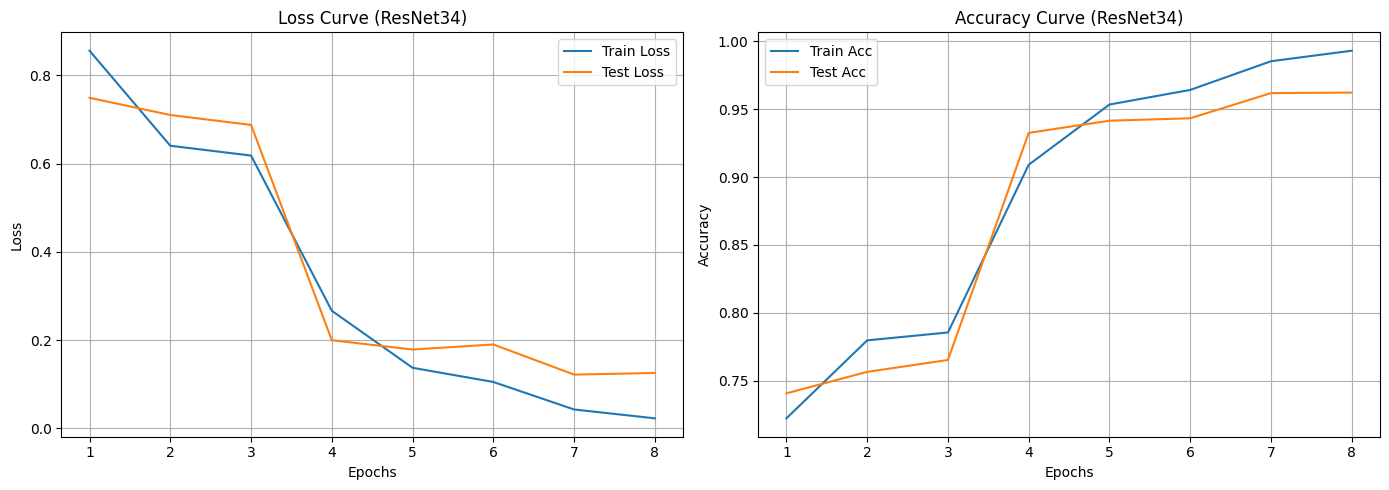

In [ ]:
# 1. Initialize ResNet34
print("=== Initializing ResNet34 ===")
model_r34 = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
model_r34.fc = nn.Linear(model_r34.fc.in_features, num_classes)
model_r34 = model_r34.to(device)

# 2. Stage 1: Frozen Backbone
print("\n=== Stage 1: Frozen Backbone (ResNet34) ===")
for name, param in model_r34.named_parameters():
    if not name.startswith("fc."):
        param.requires_grad = False

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model_r34.parameters()), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)

history_r34 = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "sec": []}
EPOCHS_STAGE1 = 3

for epoch in range(EPOCHS_STAGE1):
    tr_loss, tr_acc, sec = train_one_epoch(model_r34, train_loader, optimizer, criterion)
    te_loss, te_acc = evaluate(model_r34, test_loader, criterion)
    scheduler.step()

    history_r34["train_loss"].append(tr_loss)
    history_r34["train_acc"].append(tr_acc)
    history_r34["test_loss"].append(te_loss)
    history_r34["test_acc"].append(te_acc)
    history_r34["sec"].append(sec)

    print(f"Epoch {epoch+1}/{EPOCHS_STAGE1} | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
          f"Test Loss: {te_loss:.4f} Acc: {te_acc:.4f} | Time: {sec:.1f}s")

# 3. Stage 2: Fine-tuning
print("\n=== Stage 2: Fine-tuning (ResNet34) ===")
for param in model_r34.parameters():
    param.requires_grad = True

optimizer = optim.Adam(model_r34.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)

EPOCHS_STAGE2 = 5
for epoch in range(EPOCHS_STAGE2):
    tr_loss, tr_acc, sec = train_one_epoch(model_r34, train_loader, optimizer, criterion)
    te_loss, te_acc = evaluate(model_r34, test_loader, criterion)
    scheduler.step()

    history_r34["train_loss"].append(tr_loss)
    history_r34["train_acc"].append(tr_acc)
    history_r34["test_loss"].append(te_loss)
    history_r34["test_acc"].append(te_acc)
    history_r34["sec"].append(sec)

    print(f"Epoch {epoch+1}/{EPOCHS_STAGE2} | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
          f"Test Loss: {te_loss:.4f} Acc: {te_acc:.4f} | Time: {sec:.1f}s")

# 4. Plot Results
epochs_range = range(1, len(history_r34["train_loss"]) + 1)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_r34["train_loss"], label='Train Loss')
plt.plot(epochs_range, history_r34["test_loss"], label='Test Loss')
plt.title('Loss Curve (ResNet34)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_r34["train_acc"], label='Train Acc')
plt.plot(epochs_range, history_r34["test_acc"], label='Test Acc')
plt.title('Accuracy Curve (ResNet34)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

모델은 더 깊게파서, 모델이 object의 특징에 더 집중하도록 하자.


=== Initializing ResNet34 ===

=== Stage 1: Frozen Backbone (ResNet34) ===
Epoch 1/3 | Train Loss: 0.8467 Acc: 0.7249 | Test Loss: 0.7158 Acc: 0.7571 | Time: 77.5s
Epoch 2/3 | Train Loss: 0.6381 Acc: 0.7826 | Test Loss: 0.6728 Acc: 0.7698 | Time: 76.2s
Epoch 3/3 | Train Loss: 0.6136 Acc: 0.7896 | Test Loss: 0.6751 Acc: 0.7698 | Time: 77.2s

=== Stage 2: Fine-tuning (ResNet34) ===
Epoch 1/5 | Train Loss: 0.2688 Acc: 0.9098 | Test Loss: 0.1879 Acc: 0.9340 | Time: 77.1s
Epoch 2/5 | Train Loss: 0.1406 Acc: 0.9516 | Test Loss: 0.1749 Acc: 0.9412 | Time: 77.3s
Epoch 3/5 | Train Loss: 0.1029 Acc: 0.9644 | Test Loss: 0.1497 Acc: 0.9475 | Time: 76.9s
Epoch 4/5 | Train Loss: 0.0437 Acc: 0.9852 | Test Loss: 0.1061 Acc: 0.9632 | Time: 77.6s
Epoch 5/5 | Train Loss: 0.0234 Acc: 0.9927 | Test Loss: 0.1130 Acc: 0.9636 | Time: 77.7s


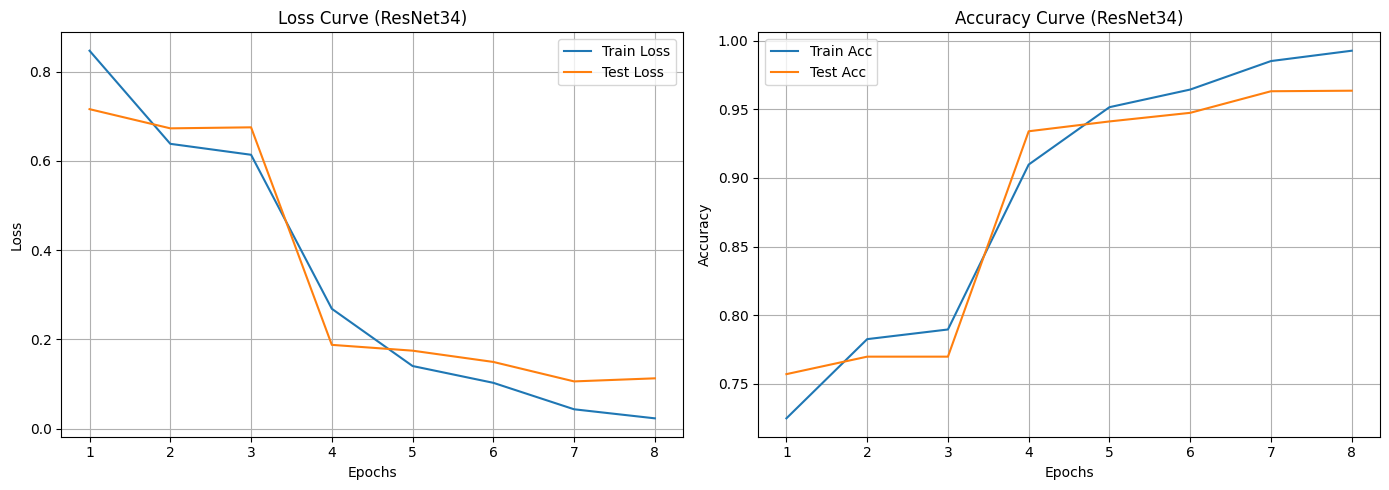

In [ ]:
# 1. Initialize ResNet34
print("=== Initializing ResNet34 ===")
model_r34 = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
model_r34.fc = nn.Linear(model_r34.fc.in_features, num_classes)
model_r34 = model_r34.to(device)

# 2. Stage 1: Frozen Backbone
print("\n=== Stage 1: Frozen Backbone (ResNet34) ===")
for name, param in model_r34.named_parameters():
    if not name.startswith("fc."):
        param.requires_grad = False

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model_r34.parameters()), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)

history_r34 = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "sec": []}
EPOCHS_STAGE1 = 3

for epoch in range(EPOCHS_STAGE1):
    tr_loss, tr_acc, sec = train_one_epoch(model_r34, train_loader, optimizer, criterion)
    te_loss, te_acc = evaluate(model_r34, test_loader, criterion)
    scheduler.step()

    history_r34["train_loss"].append(tr_loss)
    history_r34["train_acc"].append(tr_acc)
    history_r34["test_loss"].append(te_loss)
    history_r34["test_acc"].append(te_acc)
    history_r34["sec"].append(sec)

    print(f"Epoch {epoch+1}/{EPOCHS_STAGE1} | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
          f"Test Loss: {te_loss:.4f} Acc: {te_acc:.4f} | Time: {sec:.1f}s")

# 3. Stage 2: Fine-tuning
print("\n=== Stage 2: Fine-tuning (ResNet34) ===")
for param in model_r34.parameters():
    param.requires_grad = True

optimizer = optim.Adam(model_r34.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)

EPOCHS_STAGE2 = 5
for epoch in range(EPOCHS_STAGE2):
    tr_loss, tr_acc, sec = train_one_epoch(model_r34, train_loader, optimizer, criterion)
    te_loss, te_acc = evaluate(model_r34, test_loader, criterion)
    scheduler.step()

    history_r34["train_loss"].append(tr_loss)
    history_r34["train_acc"].append(tr_acc)
    history_r34["test_loss"].append(te_loss)
    history_r34["test_acc"].append(te_acc)
    history_r34["sec"].append(sec)

    print(f"Epoch {epoch+1}/{EPOCHS_STAGE2} | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
          f"Test Loss: {te_loss:.4f} Acc: {te_acc:.4f} | Time: {sec:.1f}s")

# 4. Plot Results
epochs_range = range(1, len(history_r34["train_loss"]) + 1)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_r34["train_loss"], label='Train Loss')
plt.plot(epochs_range, history_r34["test_loss"], label='Test Loss')
plt.title('Loss Curve (ResNet34)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_r34["train_acc"], label='Train Acc')
plt.plot(epochs_range, history_r34["test_acc"], label='Test Acc')
plt.title('Accuracy Curve (ResNet34)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Reasoning**:
Now that the ResNet34 model is trained, the next step is to evaluate its performance on the test set using a confusion matrix. This will allow for a comparison with the previous ResNet18 model to see if the deeper architecture reduced specific misclassifications (like Dog vs. Cat).



Generating predictions for ResNet34...


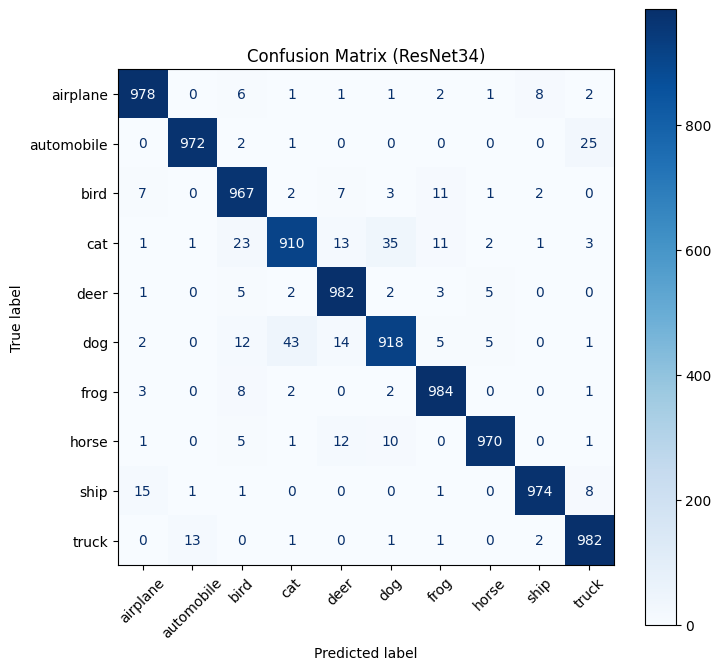

=== Top Confused Pairs (ResNet34) ===
dog        -> cat        : 43 times
cat        -> dog        : 35 times
automobile -> truck      : 25 times
cat        -> bird       : 23 times
ship       -> airplane   : 15 times
dog        -> deer       : 14 times
cat        -> deer       : 13 times
truck      -> automobile : 13 times
dog        -> bird       : 12 times
horse      -> deer       : 12 times


In [ ]:
# 1. Get predictions for ResNet34
print("Generating predictions for ResNet34...")
preds_r34, labels_r34, probs_r34 = get_predictions(model_r34, test_loader)

# 2. Compute Confusion Matrix
cm_r34 = confusion_matrix(labels_r34, preds_r34, labels=np.arange(num_classes))

# 3. Plot Confusion Matrix
disp_r34 = ConfusionMatrixDisplay(confusion_matrix=cm_r34, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8,8))
disp_r34.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
plt.title("Confusion Matrix (ResNet34)")
plt.show()

# 4. Identify Top Confused Pairs
confused_pairs_r34 = []
for i in range(num_classes):
    for j in range(num_classes):
        if i != j and cm_r34[i, j] > 0:
            confused_pairs_r34.append((cm_r34[i, j], class_names[i], class_names[j]))

confused_pairs_r34.sort(key=lambda x: x[0], reverse=True)

print("=== Top Confused Pairs (ResNet34) ===")
for count, true_cls, pred_cls in confused_pairs_r34[:10]:
    print(f"{true_cls:10s} -> {pred_cls:10s} : {count} times")

**Reasoning**:
Update the Grad-CAM configuration to target the final convolutional layer of the ResNet34 model (layer4.2.conv2). Then, visualize the top misclassification errors (Dog -> Cat) using the updated Grad-CAM and prediction data to analyze the deeper model's reasoning.



Grad-CAM re-initialized for ResNet34 @ layer4.2.conv2
Visualizing top 5 misclassified examples for dog -> cat (ResNet34)...


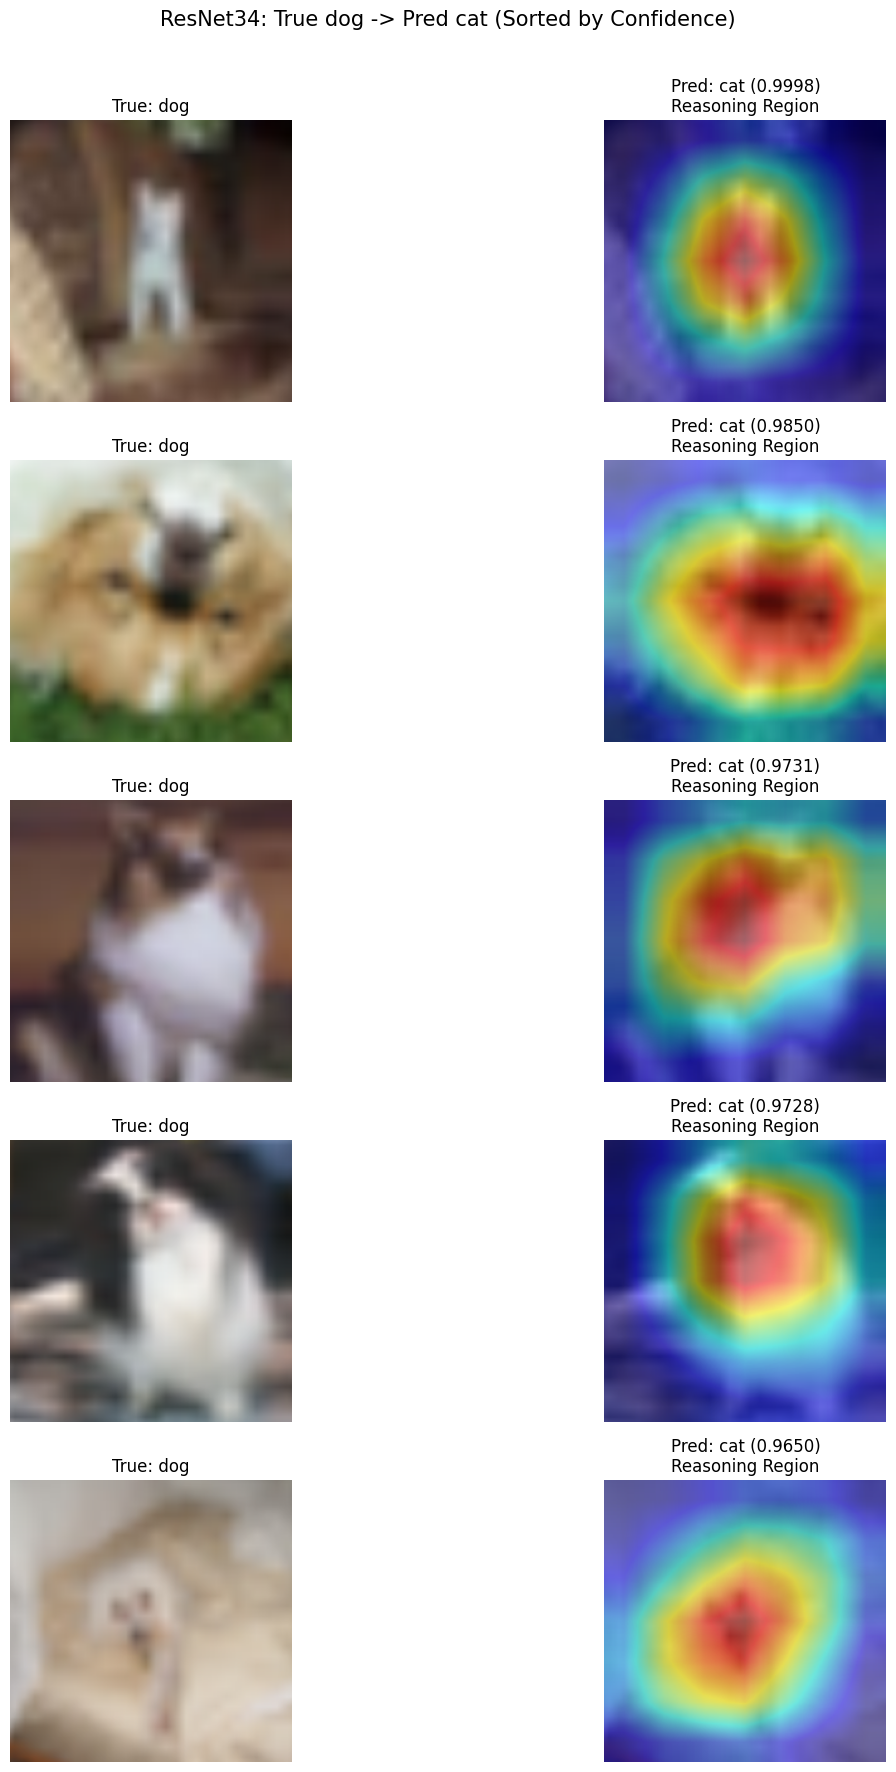

In [ ]:
# 1. Update Globals for the Visualization Function
# The function 'show_gradcam_on_errors' relies on global 'preds', 'probs', 'labels'
preds = preds_r34
probs = probs_r34
labels = labels_r34

# 2. Re-initialize GradCAM for ResNet34
# ResNet34's layer4 has 3 blocks, so the last conv is layer4.2.conv2
target_layer_name = "layer4.2.conv2"
gradcam = GradCAM(model_r34, target_layer_name)
print(f"Grad-CAM re-initialized for ResNet34 @ {target_layer_name}")

# 3. Get Top Confused Pair (Dog -> Cat)
top_true_name = "dog"
top_pred_name = "cat"
top_true_idx = class_names.index(top_true_name)
top_pred_idx = class_names.index(top_pred_name)

# 4. Find indices of errors
mistakes_r34 = np.where((labels == top_true_idx) & (preds == top_pred_idx))[0]

# Sort by confidence
mistake_probs_r34 = probs[mistakes_r34, top_pred_idx]
sorted_indices_r34 = mistakes_r34[np.argsort(mistake_probs_r34)[::-1]]

# 5. Visualize
print(f"Visualizing top 5 misclassified examples for {top_true_name} -> {top_pred_name} (ResNet34)...")
show_gradcam_on_errors(sorted_indices_r34, title_prefix=f"ResNet34: True {top_true_name} -> Pred {top_pred_name}", n=5)